# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The SpaceNet 1 dataset contains buildings annotated with polygon coordinates.

## Import the required packages

In [ ]:
from aitlas.datasets import SpaceNet1Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [12]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/SpaceNet1/train/3band",
    "csv_file" : "/home/dragik/data/FAIR_EO/SpaceNet1/train/summarydata/AOI_1_RIO_polygons_solution_3band.csv",
}
dataset = SpaceNet1Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 6940


# Show images

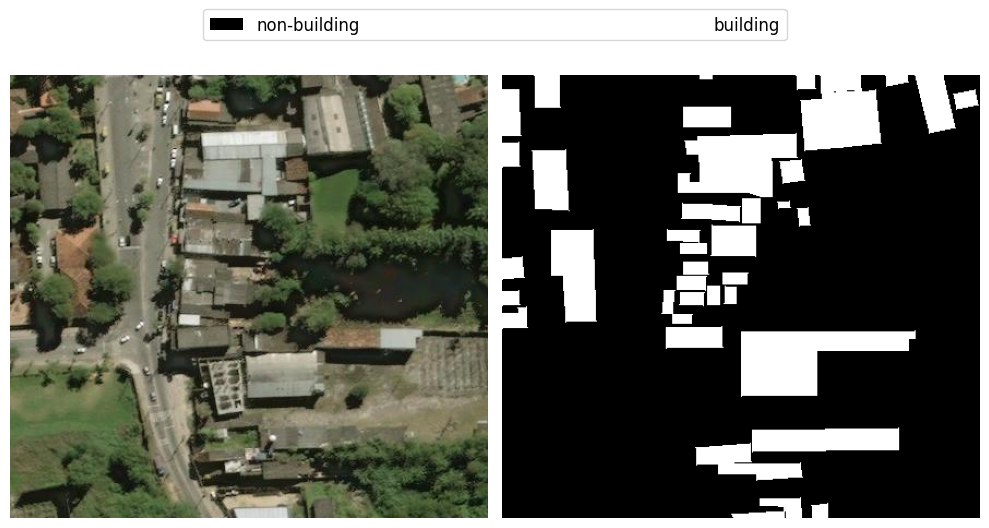

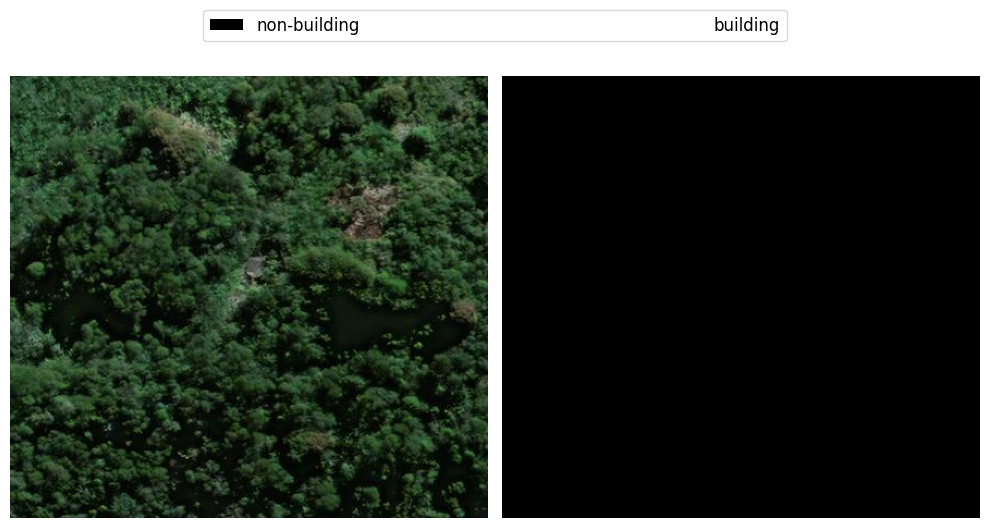

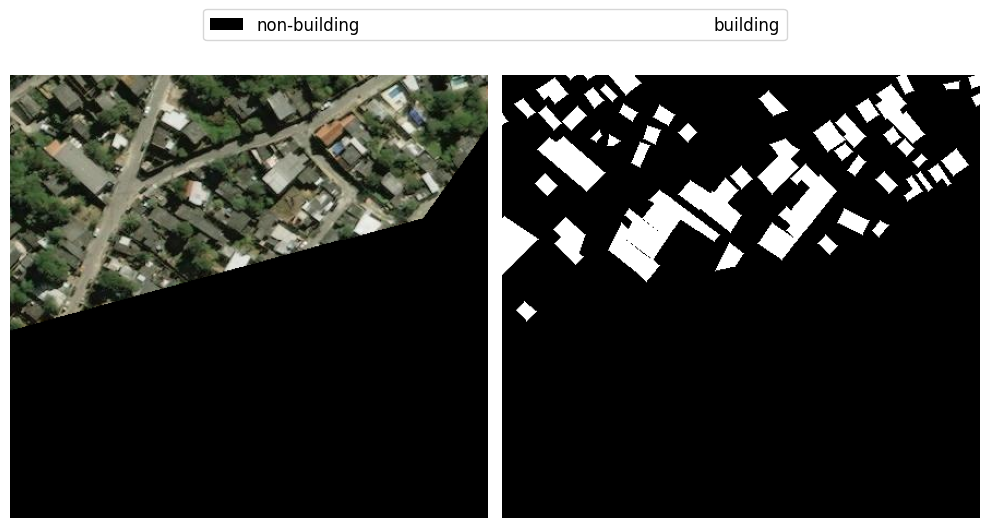

In [8]:
dataset.show_image(15);
dataset.show_image(150);
dataset.show_image(1000);

In [13]:
dataset.data_distribution_table()

,Number of pixels
non-building,1124103669
building,110022651


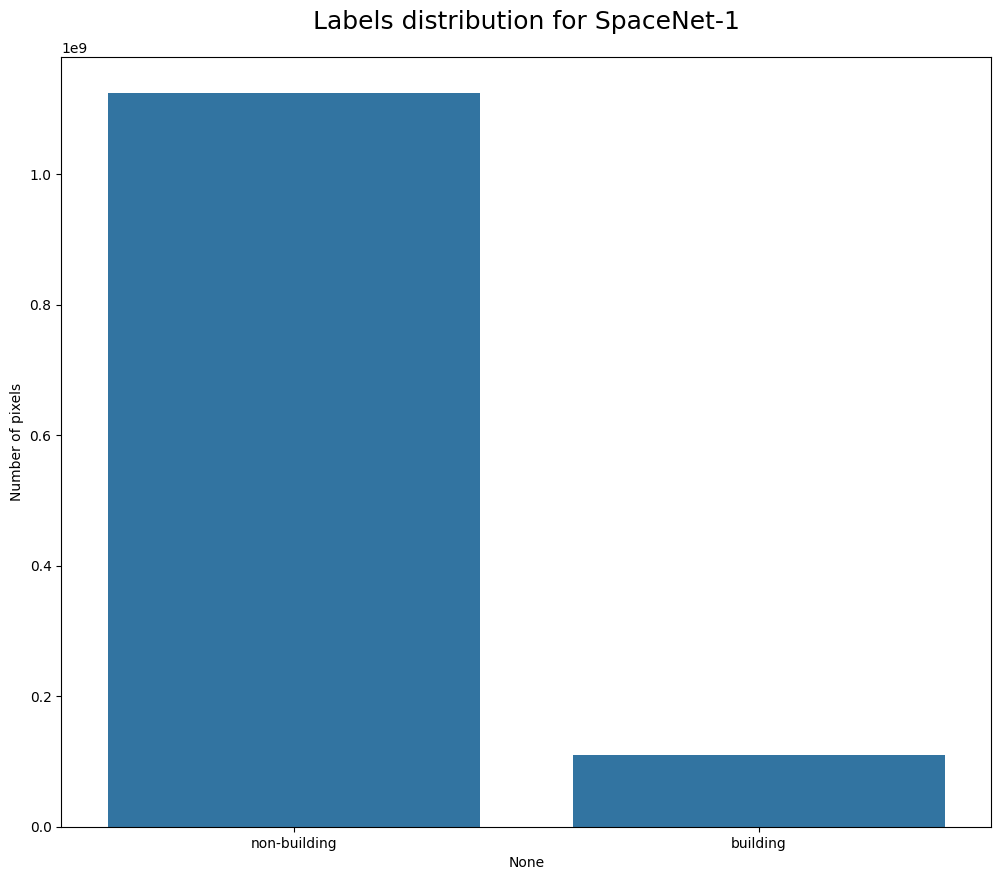

In [14]:
dataset.data_distribution_barchart();

## Load training data ##

In [18]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/SpaceNet1/train/3band",
    "csv_file" : "/home/dragik/data/FAIR_EO/SpaceNet1/train/summarydata/AOI_1_RIO_polygons_solution_3band.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet1Dataset(train_dataset_config)

len(train_dataset)

6940

## Create the model ##

In [19]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/SpaceNet1"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [20]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-22 06:45:56,952 INFO Starting training.
training: 100%|██████████| 217/217 [36:52<00:00, 10.20s/it]
2025-09-22 07:22:50,023 INFO epoch: 1, time: 2213, loss:  0.28397
testing on train set: 100%|██████████| 217/217 [37:05<00:00, 10.25s/it]
2025-09-22 07:59:56,817 INFO IOU:0.7501039744206297, IOU mean:0.6292552097447585, IOU per Class:[0.86622951 0.39228091]
training: 100%|██████████| 217/217 [37:13<00:00, 10.29s/it]
2025-09-22 08:37:10,099 INFO epoch: 2, time: 2234, loss:  0.16942
testing on train set: 100%|██████████| 217/217 [36:35<00:00, 10.12s/it]
2025-09-22 09:13:45,177 INFO IOU:0.8125826922201006, IOU mean:0.6886162395613457, IOU per Class:[0.89694343 0.48028905]
training: 100%|██████████| 217/217 [37:09<00:00, 10.27s/it]
2025-09-22 09:50:54,434 INFO epoch: 3, time: 2229, loss:  0.13298
testing on train set: 100%|██████████| 217/217 [37:08<00:00, 10.27s/it]
2025-09-22 10:28:03,114 INFO IOU:0.8171284303781867, IOU mean:0.6806769384798819, IOU per Class:[0.89172346 0.46963042

0.09221686245041553

## Predictions

2025-09-23 06:32:26,750 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet1/checkpoint.pth.tar
2025-09-23 06:32:27,320 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet1/checkpoint.pth.tar at epoch 11


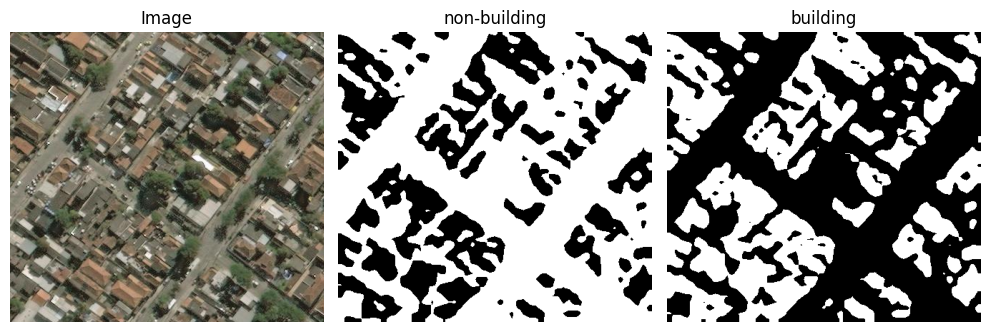

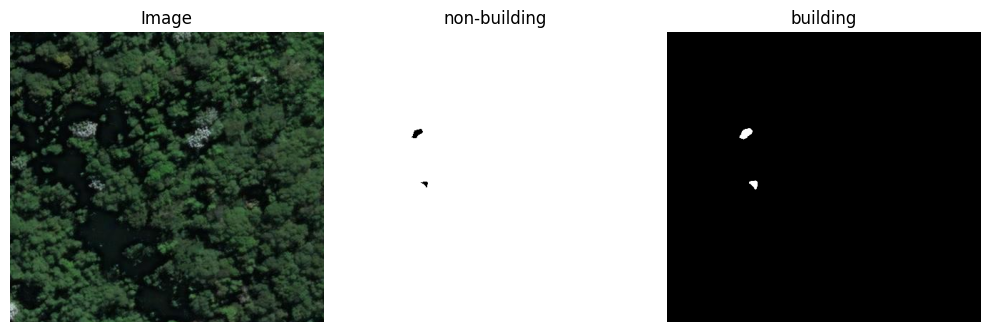

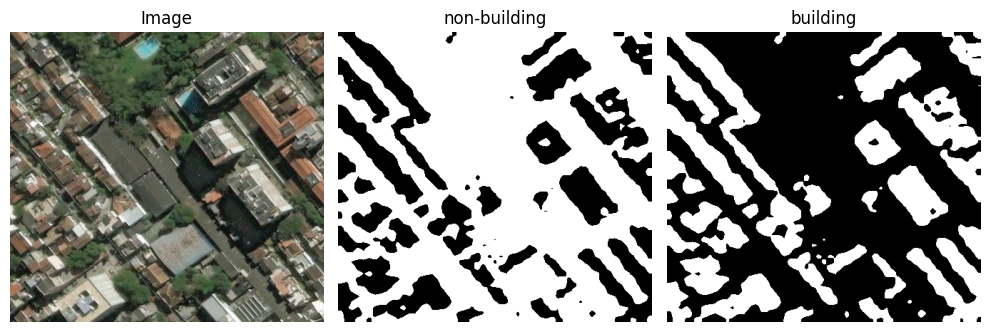

In [21]:
model_path = "/home/dragik/data/FAIR_EO/experiments/SpaceNet1/checkpoint.pth.tar"
labels = ["non-building","building"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/SpaceNet1/test_public/3band/3band_AOI_2_RIO_img5.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SpaceNet1/test_public/3band/3band_AOI_2_RIO_img25.tif')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SpaceNet1/test_public/3band/3band_AOI_2_RIO_img51.tif')
fig = model.predict_masks(image, labels, transform)